# **MÓDULO 13**
# Projeto - Fundamentos da Descoberta de Dados

Nesse projeto trabalharemos com a base de dados de produtos de um supermercado do Chile.
A ideia é que vocês apliquem os conceitos estatísticos vistos no último módulo, mais os conceitos de visualizações de dados através de gráficos e finalizem publicando no seu github!

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

Faça a leitura dos dados do arquivo CSV:


Altere o código abaixo de acordo com seu diretório.

In [27]:
df = pd.read_csv("/base_supermercado.csv")

df.head(10)

,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


Os campos do nosso dataframe são:

**Title:** Nome do produto.


**Marca:** A marca do produto.


**Preco_Normal:** O preço em que o produto costuma ser vendido quando não há desconto.


**Preco_Desconto:** O preço vendido após o desconto ser aplicado.


**Preco_Anterior:** Preço em que era comercializado o produto antes do desconto aplicado.


**Desconto:** Total de desconto aplicado.






As colunas que aparecem com valores 0 são para os produtos onde não tivemos descontos aplicados.


As categorias estão em espanhol!

# 1 - Traga a média e a mediana dos preços - coluna Preco_Normal - por categoria de produto.
# Identifique as categorias que parecem ter um valor de média abaixo ou acima da mediana.

In [28]:
media = df.groupby('Categoria')['Preco_Normal'].mean()

media


,Preco_Normal
Categoria,
belleza-y-cuidado-personal,1783.556485
comidas-preparadas,3095.043478
congelados,2108.042553
frutas,1724.473684
instantaneos-y-sopas,765.491228
lacteos,2385.219239
verduras,1343.296875


In [29]:
mediana = df.groupby('Categoria')['Preco_Normal'].median()

mediana

,Preco_Normal
Categoria,
belleza-y-cuidado-personal,1569.0
comidas-preparadas,3290.0
congelados,1519.0
frutas,1195.0
instantaneos-y-sopas,439.0
lacteos,989.0
verduras,1180.0


Digite aqui as categorias:

**Categorias com média ACIMA da mediana** (poucos produtos muito caros puxam a média para cima):
- lacteos: média ≈ 2.385 vs mediana ≈ 989 (maior diferença)
- congelados: média ≈ 2.108 vs mediana ≈ 1.519
- frutas: média ≈ 1.724 vs mediana ≈ 1.195
- instantaneos-y-sopas: média ≈ 765 vs mediana ≈ 439
- belleza-y-cuidado-personal: média ≈ 1.784 vs mediana ≈ 1.569
- verduras: média ≈ 1.343 vs mediana ≈ 1.180

**Categoria com média ABAIXO da mediana:**
- comidas-preparadas: média ≈ 3.095 vs mediana ≈ 3.290

Nas categorias com média acima da mediana, a distribuição é assimétrica à direita: existem alguns preços altos que elevam a média. Em lacteos a diferença é a mais expressiva.

# 2 - Traga o desvio padrão por categoria de produto.
# Qual o comportamento da média e mediana nas categorias com maior desvio?

In [30]:
desvio = df.groupby('Categoria')['Preco_Normal'].std()

desvio.sort_values(ascending=False)


,Preco_Normal
Categoria,
lacteos,3925.816164
belleza-y-cuidado-personal,2210.041719
congelados,2111.539896
comidas-preparadas,2019.911428
frutas,1639.151114
instantaneos-y-sopas,1170.232869
verduras,1012.699625


Digite nesse campo o comportamento que você identificou:

A categoria com maior desvio padrão é **lacteos** (≈ 3.926), seguida de belleza-y-cuidado-personal (≈ 2.210) e congelados (≈ 2.112).

Em lacteos, a média (≈ 2.385) é mais que o dobro da mediana (≈ 989). Isso mostra que os preços são muito dispersos e que há produtos com preço muito alto, que puxam a média para cima, enquanto a mediana, menos sensível a valores extremos, mostra que o produto típico custa bem menos.

Em geral, nas categorias de desvio alto, a média tende a ficar acima da mediana, porque valores extremos aumentam o desvio e deslocam a média.

In [31]:
comparacao = pd.DataFrame({
    'media': media,
    'mediana': mediana,
    'desvio_padrao': desvio
})
comparacao['media - mediana'] = comparacao['media'] - comparacao['mediana']
comparacao.sort_values('desvio_padrao', ascending=False)

,media,mediana,desvio_padrao,media - mediana
Categoria,,,,
lacteos,2385.219239,989.0,3925.816164,1396.219239
belleza-y-cuidado-personal,1783.556485,1569.0,2210.041719,214.556485
congelados,2108.042553,1519.0,2111.539896,589.042553
comidas-preparadas,3095.043478,3290.0,2019.911428,-194.956522
frutas,1724.473684,1195.0,1639.151114,529.473684
instantaneos-y-sopas,765.491228,439.0,1170.232869,326.491228
verduras,1343.296875,1180.0,1012.699625,163.296875


# 3 - Plot um boxplot da distribuição do Preco_Normal para a categoria que você identificou que tem o maior desvio padrão. Como é a distribuição desses dados segundo o boxplot? Você identifica muitos outliers?

Dica: Para trazer apenas os dados da categoria que você deseja você pode usar o df.loc[df['Categoria'] == 'CATEGORIA ESCOLHIDA'

lacteos 447
lacteos 447


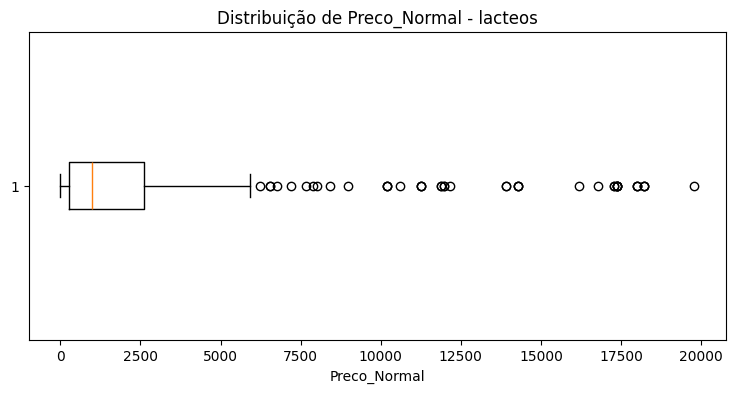

In [32]:
cat_maior = desvio.idxmax()   # nome da categoria com maior desvio

dados_cat = df.loc[df['Categoria'] == cat_maior]

print(cat_maior, len(dados_cat))

cat_maior = desvio.idxmax()
dados_cat = df.loc[df['Categoria'] == cat_maior]

print(cat_maior, len(dados_cat))

plt.figure(figsize=(9, 4))
plt.boxplot(dados_cat['Preco_Normal'], vert=False)
plt.title(f'Distribuição de Preco_Normal - {cat_maior}')
plt.xlabel('Preco_Normal')
plt.savefig('boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

In [33]:
q1 = dados_cat['Preco_Normal'].quantile(0.25)
mediana_cat = dados_cat['Preco_Normal'].median()
q3 = dados_cat['Preco_Normal'].quantile(0.75)
lim_sup = q3 + 1.5 * (q3 - q1)

print(f'Q1: {q1:.0f} | Mediana: {mediana_cat:.0f} | Q3: {q3:.0f} | Limite superior: {lim_sup:.0f}')

outliers = dados_cat[dados_cat['Preco_Normal'] > lim_sup]
print(f'Outliers: {len(outliers)} de {len(dados_cat)}')
outliers[['title', 'Marca', 'Preco_Normal']].sort_values('Preco_Normal', ascending=False).head(10)

Q1: 269 | Mediana: 989 | Q3: 2609 | Limite superior: 6119
Outliers: 43 de 447


,title,Marca,Preco_Normal
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388


O boxplot de lacteos mostra uma distribuição fortemente assimétrica à direita. A caixa é estreita e concentrada nos preços baixos (Q1 ≈ 269, mediana ≈ 989, Q3 ≈ 2.609), ou seja, a maioria dos produtos custa pouco. Acima do limite superior do bigode (≈ 6.119) aparecem muitos pontos isolados, os outliers, chegando a quase 20.000.

Sim, há muitos outliers: cerca de 43 dos 447 produtos (≈ 10%). Ao olhar os nomes, a maioria são packs, como "Pack 12 un, Leche...", ou seja, o preço é alto porque é uma embalagem com 12 unidades, e não porque o produto seja caro em si. Esses outliers explicam o maior desvio padrão da base e a distância entre média e mediana.

# 4 - Plote um gráfico de barras onde temos a média de descontos por categoria.

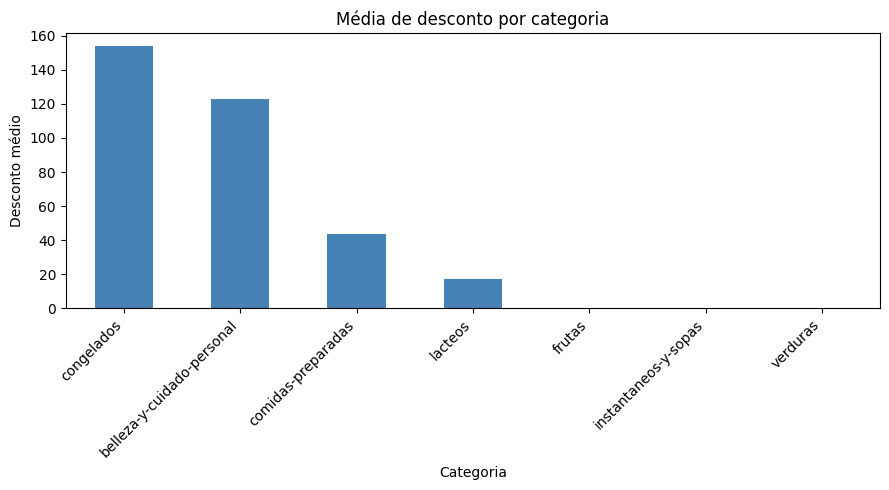

In [34]:
desc_cat = df.groupby('Categoria')['Desconto'].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
desc_cat.plot(kind='bar', color='steelblue')
plt.title('Média de desconto por categoria')
plt.ylabel('Desconto médio')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('barras_desconto.png', dpi=150)
plt.show()

O gráfico mostra que congelados (≈ 154) e belleza-y-cuidado-personal (≈ 123) têm os maiores descontos médios, seguidas de comidas-preparadas (≈ 43) e lacteos (≈ 17). As categorias frutas, instantaneos-y-sopas e verduras têm média zero, o que indica que nenhum produto delas teve desconto na base. Como os produtos sem desconto entram na média com valor 0, a média de cada categoria também depende da proporção de produtos com promoção.

# 5 - Plote um gráfico de mapa interativo agrupando os dados por categoria, marca e trazendo a média de desconto.

In [35]:
agrupado = (df.groupby(['Categoria', 'Marca'])
              .agg(desconto_medio=('Desconto', 'mean'),
                   qtd_produtos=('title', 'count'))
              .reset_index())

fig = px.treemap(
    agrupado,
    path=['Categoria', 'Marca'],
    values='qtd_produtos',
    color='desconto_medio',
    color_continuous_scale='RdYlGn',
    title='Média de desconto por categoria e marca'
)
fig.show()
fig.write_html('mapa_desconto.html')

No mapa, o tamanho de cada bloco representa a quantidade de produtos e a cor representa a média de desconto. Lacteos domina em quantidade de produtos, mas com desconto médio baixo. As categorias com maior desconto médio aparecem com cores diferentes, e é possível identificar quais marcas dentro de cada categoria concentram os maiores descontos.